## DiffGSP tutorial 1: mouse brain Visium dataset

This tutorial demonstrates how to apply **DiffGSP** to a mouse brain Visium dataset. The dataset can be obtained from the 10x Genomics Data Repository: [Mouse Brain Section (Coronal) — 10x Genomics](https://www.10xgenomics.com/datasets/mouse-brain-section-coronal-1-standard-1-1-0). For convenience, we have provided the dataset in Google Drive. You can download it directly to run this tutorial: [download the dataset](https://drive.google.com/drive/folders/1Mq_1C2iYgpTCCP7Ko2SHRwwZO3yNgLga?usp=sharing).


In [1]:
from dask import visualize

import DiffGSP as dg
import torch
import os
import numpy as np
import pandas as pd
import scanpy as sc
from pathlib import Path
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda:0


### 1. Define input and output paths

In [2]:
data_dir = Path("/home/liujixin/datasets/Visium")
res_dir = Path("/home/liujixin/project/DiffGSP/results/Visium")

data_name = "1.1.0_V1_Adult_Mouse_Brain"

data_dir = data_dir / data_name
res_dir = res_dir / data_name
res_dir.mkdir(parents=True, exist_ok=True)

### 2. Load and preprocess the Visium data

Genes detected in fewer than 10 spots are removed. The top 2,000 spatially variable genes are then selected using the SpaGFT-based SVG selection implemented in DiffGSP.

In [3]:
# set seed
dg.seed_all(42)

# load data
adata = sc.read_visium(
    data_dir,
    count_file=data_name + "_raw_feature_bc_matrix.h5"
)
adata.var_names_make_unique()

# Prefilter genes
adata = adata[:, dg.prefilter_genes(adata, min_cells=10)]

# Select the top 2,000 spatially variable genes
svgs = dg.select_svgs(
    adata,
    svg_method="gft_top",
    n_top=2000
)
adata = adata[:, svgs]
adata

View of AnnData object with n_obs × n_vars = 4992 × 2000
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'

Note that adata.obs['in_tissue'] is required for parameter learning. If there are no out-of-tissue spots in this data, please give the parameters manually.

### 3. Save the preprocessed original data

In [4]:
adata_raw = adata.copy()

adata_raw.write_h5ad(
    res_dir / f"{data_name}_Original.h5ad"
)

### 4. Run DiffGSP

The parameter `inv_cutoff` controls the extent of inverse diffusion and corresponds to the stability ratio used to determine the reconstruction cutoff. Two settings can be used:
- `inv_cutoff="auto"`: automatically determines the cutoff from the stability curve.
- A numerical value, such as `inv_cutoff=1.2`: manually specifies the cutoff.

For this mouse brain Visium dataset, `inv_cutoff=1.2` was used in the analysis.

In [5]:
adata = sc.read_h5ad(
    res_dir / f"{data_name}_Original.h5ad"
)

k = 5 # controls the diffusion step
inv = "auto" # controls the extent of inverse diffusion
adata, optimal_solution, loss_list, constant = dg.run_diffgsp(
    adata,
    gene_network=False, # do not use gene network
    k=k,
    device=device,
    method="BFGS",
    data_type="Visium",
    inv_cutoff=inv
)
# write
adata.write_h5ad(
    res_dir / f"{data_name}_DiffGSP.h5ad"
)

Training:   7%|▉             | 7/100 [00:12<02:44,  1.77s/it, Loss=tensor(31.7567, device='cuda:0')]


New para 0.10045459
Current parameters: 	 [np.float32(0.10045459), array(0.0004, dtype=float32)]


### 5. Downstream analysis

#### Visualization of representative genes

First, we visualize several representative genes to compare their spatial expression patterns before and after diffusion correction.

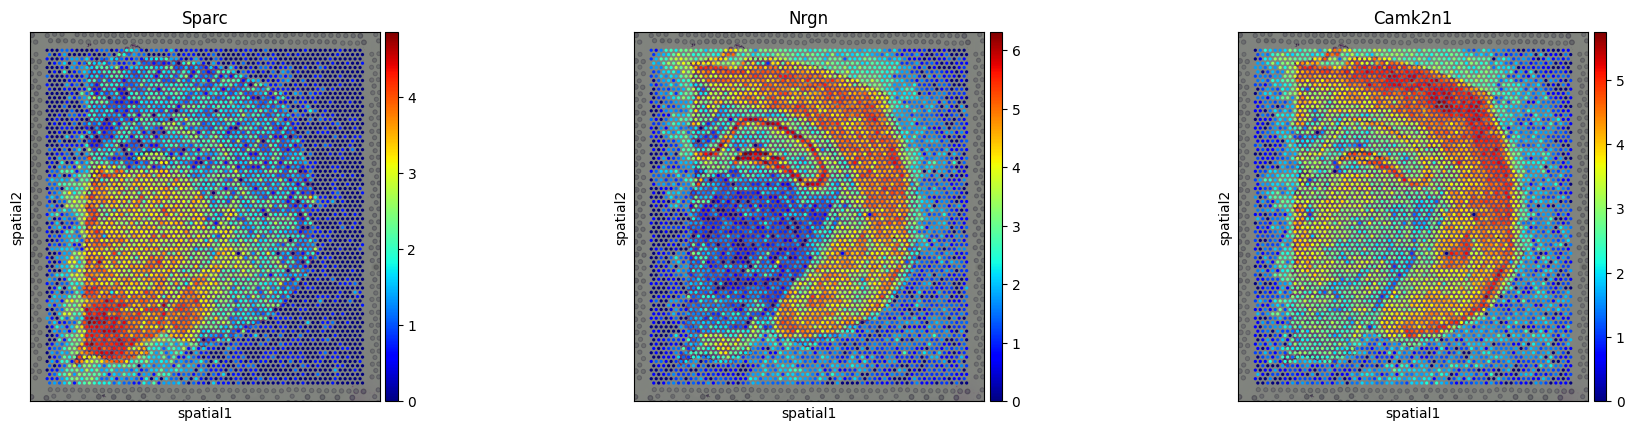

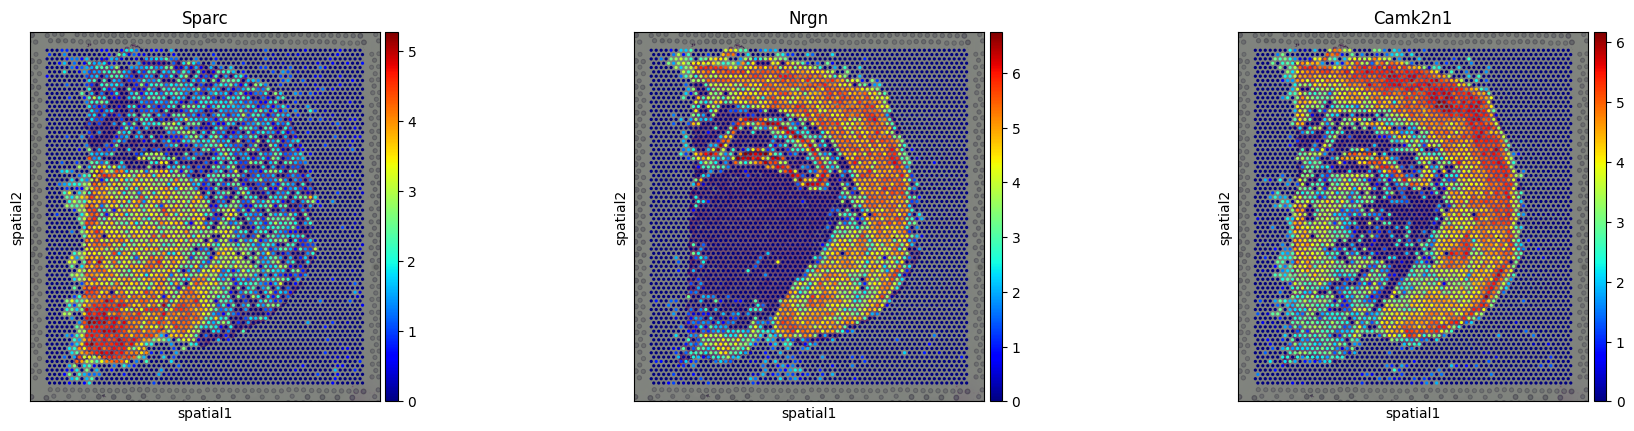

In [6]:
# load data
adata_orig = sc.read_h5ad(res_dir / f"{data_name}_Original.h5ad")
adata_diff = sc.read_h5ad(res_dir / f"{data_name}_DiffGSP.h5ad")
sc.pp.log1p(adata_orig)
sc.pp.log1p(adata_diff)

# visualization
gene_list = ["Sparc", "Nrgn", "Camk2n1"]
sc.pl.spatial(adata_orig, color=gene_list, cmap='jet')
sc.pl.spatial(adata_diff, color=gene_list, cmap='jet')

#### Spatial clustering

Next, we evaluate whether diffusion correction improves the identification of spatial domains by comparing spot clustering results obtained from the original and DiffGSP-processed data.

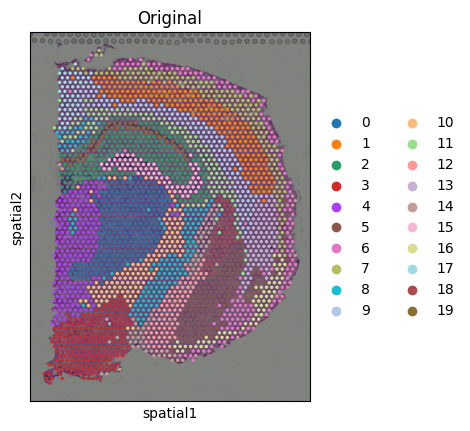

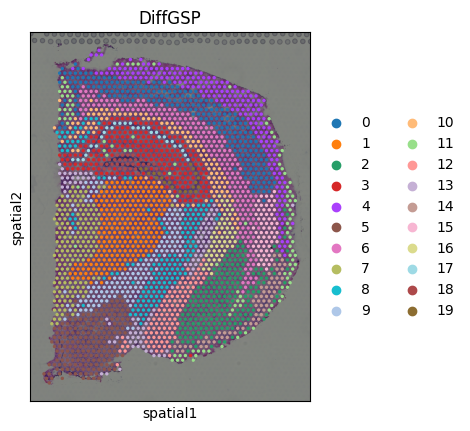

In [7]:
# load data and processing
adata_orig = sc.read_h5ad(res_dir / f"{data_name}_Original.h5ad")
adata_diff = sc.read_h5ad(res_dir / f"{data_name}_DiffGSP_inv-1.2.h5ad")
adata_orig = adata_orig[adata_orig.obs['in_tissue'] == 1, :]
adata_diff = adata_diff[adata_diff.obs['in_tissue'] == 1, :]
sc.pp.normalize_total(adata_orig)
sc.pp.normalize_total(adata_diff)
sc.pp.log1p(adata_orig)
sc.pp.log1p(adata_diff)
sc.pp.pca(adata_orig)
sc.pp.pca(adata_diff)
sc.pp.neighbors(adata_orig)
sc.pp.neighbors(adata_diff)

# clustering based on Leiden algorithm
sc.tl.leiden(adata_orig, resolution=1)
sc.tl.leiden(adata_diff, resolution=1)

sc.pl.spatial(adata_orig,
              color='leiden',
              title='Original',)
sc.pl.spatial(adata_diff,
              color='leiden',
              title='DiffGSP')


DiffGSP provides a finer delineation of spatial domains, particularly in the hippocampal CA region.

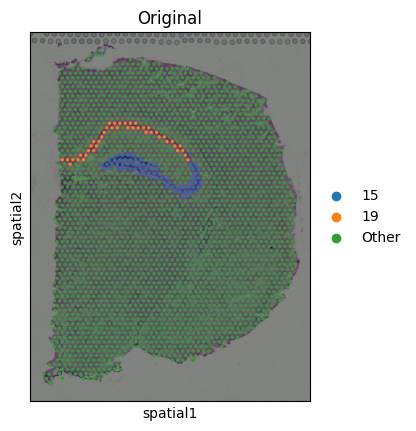

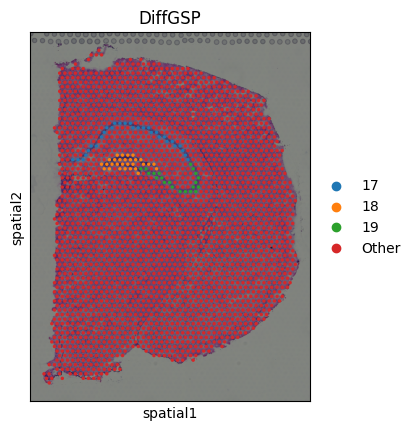

In [8]:
orig_ca_cluster = ["15", "19"]
diff_ca_cluster = ["17", "18", "19"]

adata_orig.obs["CA_cluster"] = adata_orig.obs["leiden"].astype(str)
adata_diff.obs["CA_cluster"] = adata_diff.obs["leiden"].astype(str)

adata_orig.obs.loc[
    ~adata_orig.obs["CA_cluster"].isin(orig_ca_cluster), "CA_cluster"
] = "Other"

adata_diff.obs.loc[
    ~adata_diff.obs["CA_cluster"].isin(diff_ca_cluster), "CA_cluster"
] = "Other"

adata_orig.obs["CA_cluster"] = pd.Categorical(
    adata_orig.obs["CA_cluster"],
    categories=orig_ca_cluster + ["Other"]
)

adata_diff.obs["CA_cluster"] = pd.Categorical(
    adata_diff.obs["CA_cluster"],
    categories=diff_ca_cluster + ["Other"]
)

sc.pl.spatial(
    adata_orig,
    color="CA_cluster",
    title="Original"
)

sc.pl.spatial(
    adata_diff,
    color="CA_cluster",
    title="DiffGSP"
)